# The v2 population for the ring decoder → `pool.pdf`

Run this before the decoder. It shows which neurons the v2 criterion admits and how that pool
compares with figure 3's, and it trains nothing.

## What changes, and what deliberately does not

`figure_3/motor_decoding/decoder_figures.ipynb` is explicit that it uses **one population per
animal and no wedge** — every neuron passing the shared 2-object modulation criterion. The
figure contrasts a 2-object decode against its own *additive null*, not one sub-population
against another. So the port is narrower than the titration's:

* **The pool** is the shared modulation criterion (`FDR_Q` + `MIN_DEV`), which is what makes
  this decoder describe the same neurons the model comparison describes. ρ comes from the
  comparison's held-out accuracies. A second scheme — a radial cut in the plane of the two
  models' evidence — was built and removed on 2026-09-11; it selected neurons using the very
  models being contrasted, and the shared criterion does its job harder anyway.
* **The decoder is untouched** — `fit_tuning`, `joint_fit`, `decode`, `nearest_max_errors` and
  the annulus plotting are imported from figure 3 rather than copied, so nothing about the
  read-out can drift between versions and any difference is attributable to selection.
* **A wedge is available but off** (`population_v2.wedge_pool`). "Do relational neurons carry
  the movement better?" is a real follow-up question, but it is not the figure's claim and
  turning it on silently would change what the figure means.

## The selection/evaluation split

ρ comes from the model comparison; the decoder is fit and scored on the
**other** half via `population_v2.subset_trials`. This is the same guard the
titration uses, and it matters here for the same reason: choosing neurons and scoring them on
one set of trials makes the choice partly a choice of noise.

In [1]:
import sys

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

sys.path.insert(0, '..')
import common
import selection_lib as sel
import population_v2 as pv

common.set_style()
pd.set_option('display.width', 200)

# ── CONFIG ───────────────────────────────────────────────────────────────────
USE_WEDGE = False                  # see the note above before turning this on
WEDGE_X = 0.9
FIGSIZE = (6.4, 3.2)
OUTPUT = 'pool.pdf'

## The pool

`ρ = 0` is where `arctan2(0, 0)` puts every neuron **neither** model explains, so a pool that
admits them counts them as retinotopic. They are 30.2% of Monkey E against 13.9% of Monkey P,
so leaving them in does not merely add noise, it adds *differently shaped* noise to the two
animals. The shared modulation criterion removes almost all of them: of the 665 neurons neither
model explains, it admits 6.

In [2]:
pool_df = pv.candidate_units()
if USE_WEDGE:
    pool_df = pv.wedge_pool(pool_df, WEDGE_X)
pv.pool_summary(pool_df)

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
  pool: 1339 neurons


,subject,area,n,mean_rho,median_radius
0,Monkey P,all,998,0.640056,4.370668
1,Monkey P,DMFC,593,0.667700,4.370668
2,Monkey P,FEF,405,0.599581,4.370668
3,Monkey E,all,341,0.578590,4.023437
4,Monkey E,DMFC,86,0.576510,3.965772
5,Monkey E,FEF,255,0.579291,4.023437


### How the v2 pool compares with figure 3's

**They are now the same 1339 neurons**, which is the point: `EXCLUSION = 'config'` means this
decoder and the model comparison describe one population. The check is kept because that
agreement is a property of the current settings rather than a guarantee — until 2026-09-11 the
radial cut was `prepared_pool`'s default, and this cell reported 2460 against 1339, with 1124
neurons in the decoder's pool that the model comparison excluded.

In [3]:
try:
    f3 = pv.pl.candidate_units(verbose=False)
    key = ['subject', 'session', 'unit_id']
    both = pool_df[key].merge(f3[key], on=key)
    print(f'figure 3 pool: {len(f3)}   v2 pool: {len(pool_df)}   in both: {len(both)}')
    print(f'  v2 only: {len(pool_df) - len(both)}   figure 3 only: {len(f3) - len(both)}')
except Exception as e:
    print(f'(figure 3 pool unavailable: {e})')

figure 3 pool: 1339   v2 pool: 1339   in both: 1339
  v2 only: 0   figure 3 only: 0


saved pool.pdf


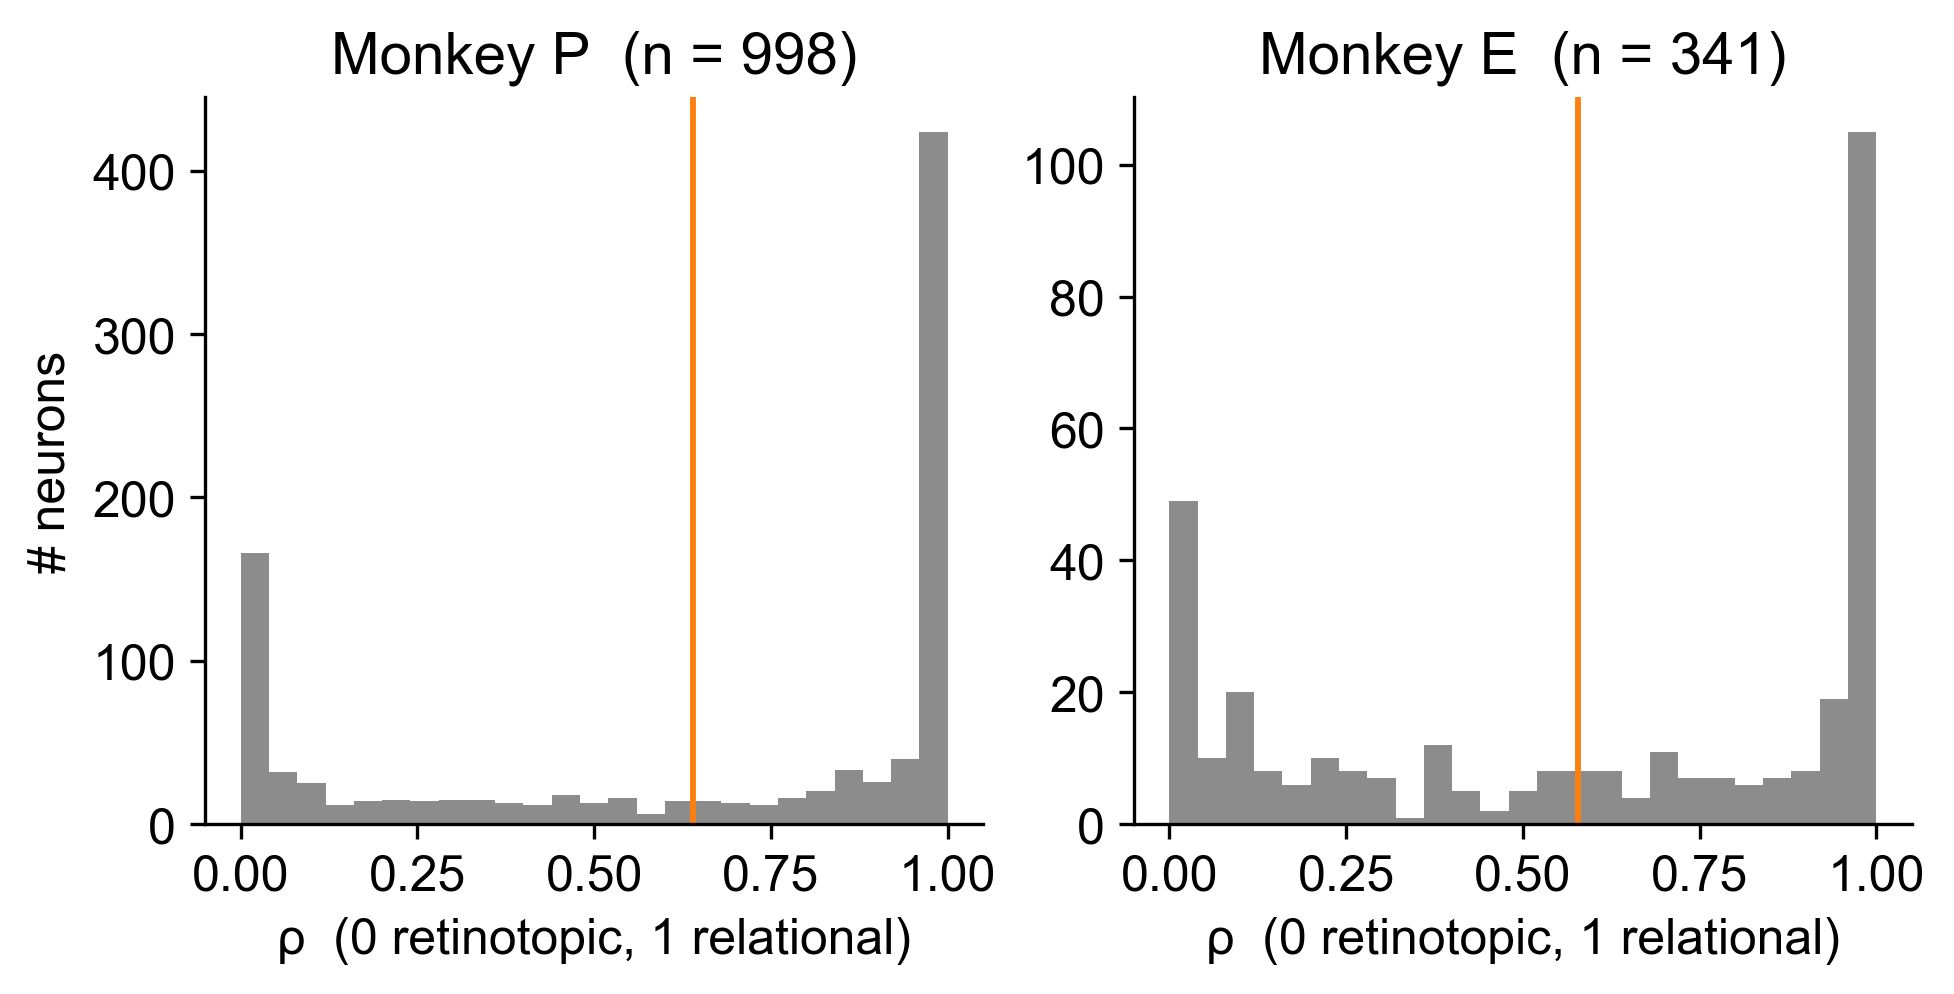

In [4]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, squeeze=False, layout='constrained')
for ci, s in enumerate(sel.ordered_subjects(pool_df)):
    g = pool_df[pool_df['subject'] == s]
    ax = axes[0][ci]
    ax.hist(g['rho'], bins=np.linspace(0, 1, 26), color='0.55', edgecolor='none')
    ax.axvline(g['rho'].mean(), color='tab:orange', lw=1.4)
    ax.set_xlabel('ρ  (0 retinotopic, 1 relational)')
    ax.set_title(f'{sel.subject_title(s)}  (n = {len(g)})')
    sel._despine(ax)
axes[0][0].set_ylabel('# neurons')
common.save(fig, OUTPUT)
plt.show()

## Next

`decoder_v2.ipynb` is a copy of `figure_3/motor_decoding/decoder_figures.ipynb` with its
`_pool` swapped for `pv.candidate_units` and its trial loads wrapped in `pv.subset_trials`.
Everything else in that notebook is the decoder and stays as it is.

Still open, and a manuscript-scope question rather than a port decision: whether to run the
**pre-cue** window, where the target is not yet known so the read-out is a memory signal
rather than a near-restatement of the movement.